In [ ]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score, mean_squared_error
from sklearn.tree import export_text
from sklearn.ensemble import RandomForestRegressor

%matplotlib inline 

In [2]:
df = pd.read_csv("car_fuel_efficiency_2026.csv") 

In [3]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [4]:
# Clean string columns
strings = df.dtypes[df.dtypes =='string'].index.tolist()
for column in strings:
    df[column] = df[column].str.lower().str.replace(' ', '_').str.replace('-', '_')

In [5]:
df.isnull().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [6]:
numerical = [
        'model_year', 'num_doors','engine_displacement', 'num_cylinders', 
        'horsepower', 'vehicle_weight', 'acceleration', 'fuel_efficiency_mpg'
       ]

for col in numerical:
    df[col] = df[col].fillna(0.0)

In [7]:
df.isnull().sum()

model_year             0
origin                 0
fuel_type              0
drivetrain             0
num_doors              0
engine_displacement    0
num_cylinders          0
horsepower             0
vehicle_weight         0
acceleration           0
fuel_efficiency_mpg    0
dtype: int64

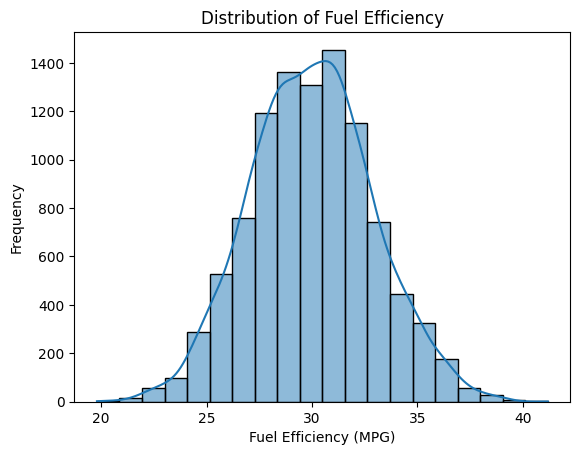

In [8]:
# plot the distribution of fuel efficiency
sns.histplot(df['fuel_efficiency_mpg'], bins=20, kde=True)
plt.title('Distribution of Fuel Efficiency')
plt.xlabel('Fuel Efficiency (MPG)')
plt.ylabel('Frequency')
plt.show()

In [9]:
# Train/validation/test split
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=11)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=11)

# reset index
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [10]:

# prepare target variable
target = 'fuel_efficiency_mpg'
y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values



In [11]:
X_train = df_train.drop(columns=[target])
X_val = df_val.drop(columns=[target])
X_test = df_test.drop(columns=[target])

In [13]:
dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(X_train.to_dict(orient='records'))
X_val = dv.transform(X_val.to_dict(orient='records'))
X_test = dv.transform(X_test.to_dict(orient='records'))

**Q1**

In [18]:
tree = DecisionTreeRegressor(max_depth=1)
tree.fit(X_train, y_train)

split_index = tree.tree_.feature[0]
split_feature = dv.get_feature_names_out()[split_index]

# Map a one-hot feature (for example, "origin=usa") to its original column.
original_feature = split_feature.split("=", 1)[0]
print(f"Split feature: {split_feature}")
print(f"Original feature: {original_feature}")

Split feature: model_year
Original feature: model_year


**Q2**

In [ ]:
rf = RandomForestRegressor(n_estimators= 10, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

In [ ]:
y_pred = rf.predict(X_val)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
print(rmse)